# E1 — Image classification with Softmax, MLP and CNN

Softmax, MLP and CNN are trained from scratch on Fashion-MNIST and compared on the same split. AI assistance is disclosed in [AI_USE_REPORT.md](../AI_USE_REPORT.md).

## Experimental protocol

All models are trained for 30 epochs with batch size 256, seeds 42, 43 and 44, and a shared data split.

In [1]:
from pathlib import Path
import subprocess
import sys

colab_root = Path("/content/CO5085-deep-learning")
roots = (Path.cwd(), *Path.cwd().parents, colab_root)
ROOT = next(
    (path for path in roots if (path / "configs/experiments.json").is_file()), None
)
if ROOT is None and "google.colab" in sys.modules:
    subprocess.run(
        [
            "git",
            "clone",
            "--depth",
            "1",
            "https://github.com/dathuynh1108/CO5085-deep-learning.git",
            str(colab_root),
        ],
        check=True,
    )
    ROOT = colab_root
if ROOT is None:
    raise FileNotFoundError(
        "Open the notebook from the CO5085-deep-learning directory."
    )
sys.path.insert(0, str(ROOT / "src"))
sys.path.insert(0, str(ROOT / "notebooks"))

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import torch
from IPython.display import Image
from IPython.display import display

from common.config import get_experiment
from common.config import load_experiments
from common.data import CLASS_NAMES
from common.data import prepare_data
from common.engine import train
from common.evaluation import evaluate_run
from common.factory import build_model
from common.factory import parameter_count
from common.runtime import atomic_csv
from common.runtime import atomic_json
from common.runtime import choose_device
from common.runtime import environment_info
from common.runtime import seed_everything
from exercise_notebook import flag
from exercise_notebook import read_json
from exercise_notebook import setting
from exercise_notebook import show_comparison
from exercise_notebook import show_figure
from exercise_notebook import show_results
from exercise_notebook import verified_training_status

EXERCISE = "E1"

In [3]:
SEEDS = tuple(int(value) for value in setting("SEEDS", "42,43,44").split(","))
MODELS = setting("MODELS")
EPOCHS = int(setting("EPOCHS")) if setting("EPOCHS") else None
DEVICE = setting("DEVICE", "auto")
WORKERS = int(setting("WORKERS", "0"))
DATA_ROOT = (ROOT / setting("DATA_ROOT", "data")).resolve()
OUTPUT_ROOT = (ROOT / setting("OUTPUT_ROOT", "runs/notebooks/exercises")).resolve()
RESUME = flag("RESUME")
DETERMINISTIC = flag("DETERMINISTIC")
DOWNLOAD = flag("DOWNLOAD", default=True)
CONFIRM_TEST = flag("CONFIRM_TEST")

In [4]:
if (
    not SEEDS
    or len(set(SEEDS)) != len(SEEDS)
    or any(not 0 <= seed < 2**32 for seed in SEEDS)
):
    raise ValueError("SEEDS must contain distinct seeds in [0, 2**32).")
SEEDS = tuple(sorted(SEEDS))
if EPOCHS is not None and OUTPUT_ROOT == (ROOT / "runs/notebooks/exercises").resolve():
    raise ValueError(
        "Changing EPOCHS requires a separate OUTPUT_ROOT for the check run."
    )
if OUTPUT_ROOT.is_relative_to((ROOT / "runs" / "exercises").resolve()):
    raise ValueError(
        "Choose an OUTPUT_ROOT outside the historical results directory runs/exercises."
    )
if WORKERS < 0:
    raise ValueError("WORKERS must be a non-negative integer.")
if CONFIRM_TEST and EPOCHS is not None:
    raise ValueError(
        "Runs with an EPOCHS override can only be evaluated on the validation set."
    )
device = choose_device(DEVICE)

In [5]:
presets = load_experiments()
allowed = {row.id for row in presets if row.exercise == EXERCISE}
if EXERCISE == "E3":
    allowed.update({"e1_mlp", "e1_cnn"})
selected = (
    tuple(value.strip() for value in MODELS.split(","))
    if MODELS
    else tuple(row.id for row in presets if row.id in allowed)
)
if len(set(selected)) != len(selected) or set(selected) - allowed:
    raise ValueError(f"MODELS must contain distinct IDs from: {sorted(allowed)}")
configs = [get_experiment(identifier, epochs=EPOCHS) for identifier in selected]
display(
    {
        "device": str(device),
        "seed": SEEDS,
        "worker": WORKERS,
        "output_root": str(OUTPUT_ROOT),
    }
)
display(
    [
        {
            key: config.to_dict()[key]
            for key in (
                "id",
                "epochs",
                "batch_size",
                "lr",
                "tokenizer",
                "backend",
                "group",
            )
        }
        for config in configs
    ]
)

{'device': 'cuda',
 'seed': (42, 43, 44),
 'worker': 4,
 'output_root': '/workspace/co5085/runs/notebooks/exercises'}

[{'id': 'e1_softmax',
  'epochs': 30,
  'batch_size': 256,
  'lr': 0.001,
  'tokenizer': 'rows',
  'backend': 'manual',
  'group': 'required'},
 {'id': 'e1_mlp',
  'epochs': 30,
  'batch_size': 256,
  'lr': 0.001,
  'tokenizer': 'rows',
  'backend': 'manual',
  'group': 'required'},
 {'id': 'e1_cnn',
  'epochs': 30,
  'batch_size': 256,
  'lr': 0.001,
  'tokenizer': 'rows',
  'backend': 'manual',
  'group': 'required'}]

## Fashion-MNIST data exploration

The stratified split contains 54,000 training and 6,000 validation images; normalization uses training statistics, and 10,000 separate test images are used for evaluation.

In [6]:
split_seeds = {config.split_seed for config in configs}
if len(split_seeds) != 1:
    raise ValueError("Comparisons require the same data split.")
train_set, validation_set, dataset = prepare_data(
    DATA_ROOT, split_seeds.pop(), DOWNLOAD
)
train_counts = np.bincount(
    train_set.labels.numpy()[train_set.indices], minlength=len(CLASS_NAMES)
)
validation_counts = np.bincount(
    validation_set.labels.numpy()[validation_set.indices], minlength=len(CLASS_NAMES)
)
display(
    {
        key: dataset[key]
        for key in ("n_train", "n_validation", "mean", "std", "fingerprint")
    }
)

0.1%

0.2%

0.4%

0.5%

0.6%

0.7%

... (935 outputs left out)

99.3%

100.0%

100.0%

{'n_train': 54000,
 'n_validation': 6000,
 'mean': 0.2858728124583167,
 'std': 0.3528899747734446,
 'fingerprint': 'd4c63c5dac60102d9ae0cd935311a9eac958b8a81b8577c047e3c2b0056dc50e'}

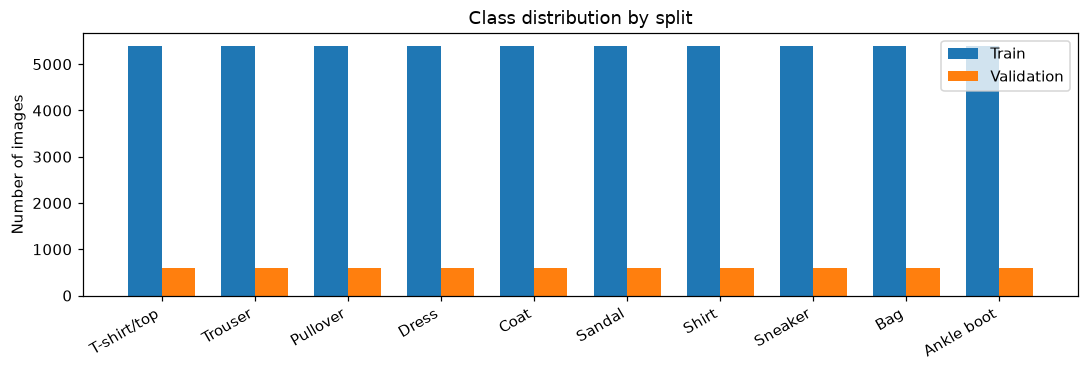

In [7]:
fig, ax = plt.subplots(figsize=(10, 3.5))
labels = np.arange(len(CLASS_NAMES))
ax.bar(labels - 0.18, train_counts, 0.36, label="Train")
ax.bar(labels + 0.18, validation_counts, 0.36, label="Validation")
ax.set_xticks(labels, CLASS_NAMES, rotation=30, ha="right")
ax.set(ylabel="Number of images", title="Class distribution by split")
ax.legend()
fig.tight_layout()
show_figure(fig)

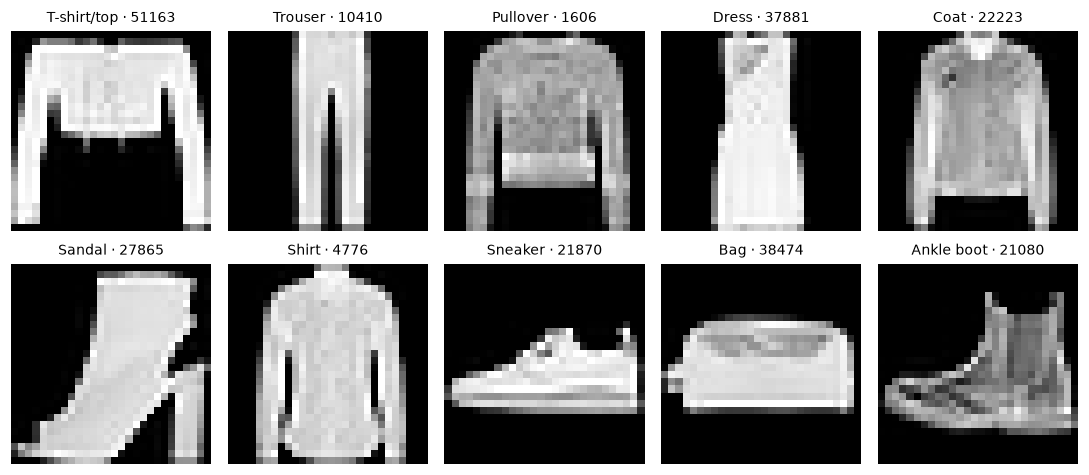

In [8]:
rng = np.random.default_rng(2026)
y = train_set.labels.numpy()
fig, axes = plt.subplots(2, 5, figsize=(10, 4.5))
for cls, ax in enumerate(axes.flat):
    index = int(rng.choice(train_set.indices[y[train_set.indices] == cls]))
    ax.imshow(train_set.images[index], cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"{CLASS_NAMES[cls]} · {index}", fontsize=9)
    ax.axis("off")
fig.tight_layout()
show_figure(fig)

## Model architectures

Softmax and MLP receive flattened pixels; the CNN preserves the image grid through two convolutional blocks.

In [9]:
seed_everything(SEEDS[0], DETERMINISTIC)
images = torch.stack([train_set[i][0] for i in range(4)])
model_shapes = []
with torch.inference_mode():
    for config in configs:
        model = build_model(config).eval()
        row = {
            "experiment": config.id,
            "parameters": parameter_count(model),
            "logits": list(model(images).shape),
        }
        model_shapes.append(row)
display(model_shapes)

[{'experiment': 'e1_softmax', 'parameters': 7850, 'logits': [4, 10]},
 {'experiment': 'e1_mlp', 'parameters': 235146, 'logits': [4, 10]},
 {'experiment': 'e1_cnn', 'parameters': 421738, 'logits': [4, 10]}]

## Training and checkpoint selection

Checkpoints are selected by validation accuracy, with lower cross-entropy breaking ties.

In [10]:
run_environment = environment_info(device)
directories = {}
for config in configs:
    for seed in SEEDS:
        directory = OUTPUT_ROOT / config.id / f"seed_{seed}"
        status = verified_training_status(
            directory,
            config,
            seed,
            dataset,
            WORKERS,
            DETERMINISTIC,
            run_environment,
        )
        if status == "trained":
            print(f"Reusing completed run: {config.id}, seed={seed}", flush=True)
        else:
            if status == "incomplete" and not RESUME:
                raise RuntimeError(
                    f"Incomplete run: {directory}. Enable RESUME to continue."
                )
            directory = train(
                config,
                seed,
                DATA_ROOT,
                OUTPUT_ROOT,
                device_name=DEVICE,
                workers=WORKERS,
                resume=status == "incomplete",
                deterministic=DETERMINISTIC,
                download=DOWNLOAD,
            )
        directories[(config.id, seed)] = directory

e1_softmax | seed=42 | cuda | parameters=7,850


  01/30: CE=0.6118 | val=83.2333% | 0.6s


  02/30: CE=0.4588 | val=84.4667% | 0.3s


  03/30: CE=0.4354 | val=85.1833% | 0.3s


  04/30: CE=0.4215 | val=85.5333% | 0.3s


  05/30: CE=0.4135 | val=85.6167% | 0.3s


... (269 outputs left out)

  27/30: CE=0.0203 | val=92.9167% | 0.5s


  28/30: CE=0.0190 | val=93.0833% | 0.5s


  29/30: CE=0.0183 | val=92.9500% | 0.5s


  30/30: CE=0.0179 | val=92.9167% | 0.5s


## Evaluation and error analysis

The comparison includes accuracy across seeds, parameter counts, training time, learning curves, confusion matrices and misclassified images.

In [11]:
split = "test" if CONFIRM_TEST else "validation"
report_dir = (
    OUTPUT_ROOT
    / "notebook_analysis"
    / EXERCISE
    / ("seeds_" + "_".join(map(str, SEEDS)))
    / split
)
evaluations, results = {}, []
for (identifier, seed), directory in directories.items():
    result = evaluate_run(
        directory,
        DATA_ROOT,
        split=split,
        confirm_test=CONFIRM_TEST,
        device_name=DEVICE,
        workers=WORKERS,
        download=DOWNLOAD,
    )
    evaluations[(identifier, seed)] = result
    training = read_json(directory / "metrics.json")
    results.append(
        {
            "experiment": identifier,
            "seed": seed,
            "split": split,
            "best_epoch": result["best_epoch"],
            "accuracy": result["accuracy"],
            "macro_f1": result["macro_f1"],
            "cross_entropy": result["cross_entropy"],
            "n_parameters": training["n_parameters"],
            "median_train_seconds": training["median_train_seconds"],
            "total_train_seconds": training["total_train_seconds"],
            "inference_images_per_second": result["inference_images_per_second"],
            "signature": result["signature"],
            "model_sha256": result["model_sha256"],
        }
    )

seed_42 test: accuracy=84.4500%, macro-F1=0.8437


seed_43 test: accuracy=84.4000%, macro-F1=0.8418


seed_44 test: accuracy=84.6800%, macro-F1=0.8454


seed_42 test: accuracy=89.9200%, macro-F1=0.8988


seed_43 test: accuracy=90.0000%, macro-F1=0.8997


seed_44 test: accuracy=89.7200%, macro-F1=0.8970


seed_42 test: accuracy=92.6600%, macro-F1=0.9266


seed_43 test: accuracy=92.7500%, macro-F1=0.9273


seed_44 test: accuracy=92.6500%, macro-F1=0.9264


In [12]:
atomic_csv(report_dir / "results.csv", results)
atomic_json(
    report_dir / "protocol.json",
    {
        "notebook": f"{EXERCISE}.ipynb",
        "configurations": [config.to_dict() for config in configs],
        "seeds": list(SEEDS),
        "dataset": dataset,
        "device": str(device),
        "workers": WORKERS,
        "deterministic": DETERMINISTIC,
        "split": split,
        "confirm_test": CONFIRM_TEST,
    },
)
show_results(results)

| Configuration | Seed | Parameters | Accuracy mean ± SD (%) | Macro-F1 mean ± SD | Median training seconds/epoch |
| --- | --- | ---: | ---: | ---: | ---: |
| e1_softmax | 42, 43, 44 | 7,850 | 84.510 ± 0.149 | 0.844 ± 0.002 | 0.28 |
| e1_mlp | 42, 43, 44 | 235,146 | 89.880 ± 0.144 | 0.899 ± 0.001 | 0.36 |
| e1_cnn | 42, 43, 44 | 421,738 | 92.687 ± 0.055 | 0.927 ± 0.000 | 0.47 |

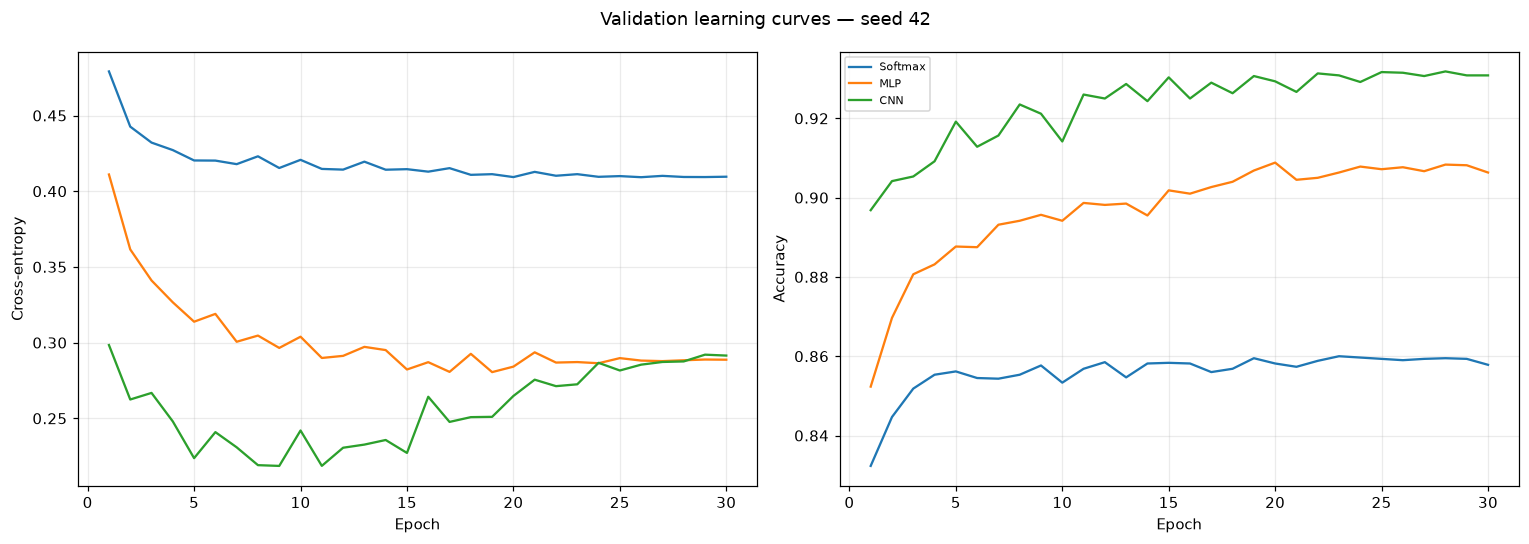

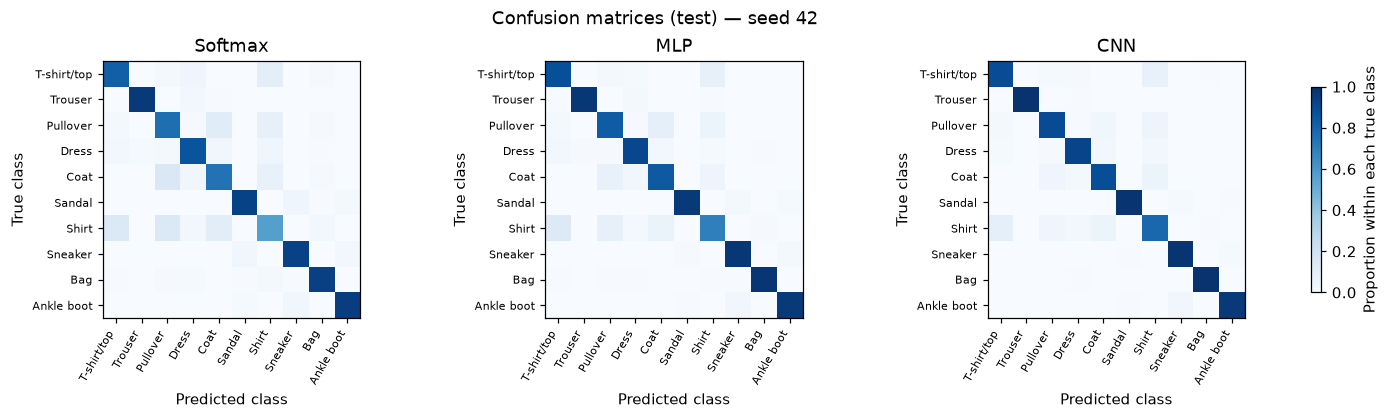

In [13]:
representative_seed = min(SEEDS)
show_comparison(configs, directories, evaluations, representative_seed, report_dir)

Errors with high prediction confidence: e1_softmax, seed=42


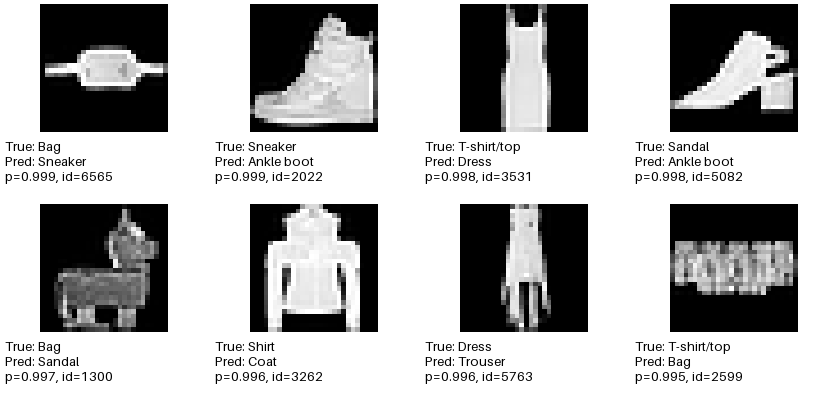

In [14]:
reference = configs[0].id
examples = (
    directories[(reference, representative_seed)] / "plots" / f"mistakes_{split}.png"
)
if examples.is_file():
    print(
        f"Errors with high prediction confidence: {reference}, seed={representative_seed}"
    )
    display(Image(filename=str(examples), width=650))

## Comparison limits

Architecture and parameter count vary together, so differences in accuracy reflect both factors.